In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# 1. Load the three datasets
sales_df = pd.read_csv('Dataset (sales).csv')
stores_df = pd.read_csv('Dataset (stores).csv')
features_df = pd.read_csv('Dataset (Features).csv')

# 2. Display basic information and shape of each dataset
print("--- Sales Dataset ---")
print(f"Shape: {sales_df.shape}")
display(sales_df.head(3))

print("\n--- Stores Dataset ---")
print(f"Shape: {stores_df.shape}")
display(stores_df.head(3))

print("\n--- Features Dataset ---")
print(f"Shape: {features_df.shape}")
display(features_df.head(3))

--- Sales Dataset ---
Shape: (156000, 5)


,store_id,department,date,weekly_sales,is_holiday
0,1,1,2022-01-01,119075.96,1
1,1,2,2022-01-01,119107.85,1
2,1,3,2022-01-01,84369.88,1



--- Stores Dataset ---
Shape: (50, 4)


,store_id,store_type,store_size,region
0,1,A,213810,North
1,2,C,31639,East
2,3,B,102098,South



--- Features Dataset ---
Shape: (7800, 14)


,store_id,date,temperature,fuel_price,markdown_1,markdown_2,markdown_3,markdown_4,markdown_5,cpi,unemployment,is_holiday,holiday_name,season
0,1,2022-01-01,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
1,1,2022-01-08,46.03,3.67,1356.75,2486.21,1427.01,983.27,2442.13,196.91,8.62,0,NaN,Winter
2,1,2022-01-15,25.96,5.46,3861.22,596.15,22.09,2854.11,3180.86,267.48,8.40,0,NaN,Winter


In [2]:
# 1. Convert 'date' column to datetime format in sales and features datasets
sales_df['date'] = pd.to_datetime(sales_df['date'])
features_df['date'] = pd.to_datetime(features_df['date'])

# 2. Check for missing values in each dataset
print("--- Missing Values in Sales Dataset ---")
print(sales_df.isnull().sum())

print("\n--- Missing Values in Stores Dataset ---")
print(stores_df.isnull().sum())

print("\n--- Missing Values in Features Dataset ---")
print(features_df.isnull().sum())

# 3. Check for duplicate rows
print(f"\nDuplicate rows in Sales: {sales_df.duplicated().sum()}")
print(f"Duplicate rows in Stores: {stores_df.duplicated().sum()}")
print(f"Duplicate rows in Features: {features_df.duplicated().sum()}")

--- Missing Values in Sales Dataset ---
store_id        0
department      0
date            0
weekly_sales    0
is_holiday      0
dtype: int64

--- Missing Values in Stores Dataset ---
store_id      0
store_type    0
store_size    0
region        0
dtype: int64

--- Missing Values in Features Dataset ---
store_id           0
date               0
temperature        0
fuel_price         0
markdown_1         0
markdown_2         0
markdown_3         0
markdown_4         0
markdown_5         0
cpi                0
unemployment       0
is_holiday         0
holiday_name    6900
season             0
dtype: int64

Duplicate rows in Sales: 0
Duplicate rows in Stores: 0
Duplicate rows in Features: 0


In [3]:
# 1. Merge sales dataset with stores dataset on 'store_id'
master_df = pd.merge(sales_df, stores_df, on='store_id', how='left')

# 2. Merge the resulting dataframe with features dataset on 'store_id' and 'date'
master_df = pd.merge(master_df, features_df, on=['store_id', 'date'], how='left', suffixes=('', '_feat'))

# Drop duplicate 'is_holiday' and the text 'holiday_name' column to keep data clean
columns_to_drop = [col for col in ['is_holiday_feat', 'holiday_name'] if col in master_df.columns]
if columns_to_drop:
    master_df = master_df.drop(columns=columns_to_drop)

# 3. Display shape and first few rows of the master dataframe
print(f"Master Dataset Shape: {master_df.shape}")
display(master_df.head(3))

Master Dataset Shape: (156000, 18)


,store_id,department,date,weekly_sales,is_holiday,store_type,store_size,region,temperature,fuel_price,markdown_1,markdown_2,markdown_3,markdown_4,markdown_5,cpi,unemployment,season
0,1,1,2022-01-01,119075.96,1,A,213810,North,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,Winter
1,1,2,2022-01-01,119107.85,1,A,213810,North,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,Winter
2,1,3,2022-01-01,84369.88,1,A,213810,North,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,Winter


In [4]:
# 1. Display descriptive statistics of numerical columns
display(master_df.describe())

# 2. Check missing values in the master dataframe
print("--- Missing Values in Master Dataset ---")
print(master_df.isnull().sum()[master_df.isnull().sum() > 0])

,store_id,department,date,weekly_sales,is_holiday,store_size,temperature,fuel_price,markdown_1,markdown_2,markdown_3,markdown_4,markdown_5,cpi,unemployment
count,156000.000000,156000.0000,156000,156000.000000,156000.000000,156000.000000,156000.000000,156000.000000,156000.000000,156000.000000,156000.000000,156000.000000,156000.000000,156000.000000,156000.000000
mean,25.500000,10.5000,2023-06-27 11:59:59.999999744,56503.488802,0.115385,136626.440000,59.875755,3.986344,2831.840176,1708.091033,2295.922200,1982.042679,2561.790629,240.469559,6.485572
min,1.000000,1.0000,2022-01-01 00:00:00,819.660000,0.000000,31639.000000,20.020000,2.500000,0.180000,0.200000,1.010000,1.130000,0.140000,180.000000,3.000000
25%,13.000000,5.7500,2022-09-29 06:00:00,21255.962500,0.000000,91417.000000,39.942500,3.240000,1308.727500,787.155000,1095.917500,969.917500,1198.375000,211.027500,4.720000
50%,25.500000,10.5000,2023-06-27 12:00:00,43394.870000,0.000000,140736.500000,60.065000,3.970000,2652.495000,1612.570000,2174.595000,1862.980000,2417.900000,240.945000,6.490000
75%,38.000000,15.2500,2024-03-24 18:00:00,79604.107500,0.000000,179797.000000,79.910000,4.750000,4027.545000,2423.002500,3212.695000,2790.137500,3600.245000,270.445000,8.220000
max,50.000000,20.0000,2024-12-21 00:00:00,505958.730000,1.000000,218696.000000,99.970000,5.500000,10977.070000,6599.720000,8798.150000,7692.880000,9891.190000,299.990000,10.000000
std,14.430916,5.7663,NaN,46717.490663,0.319487,53081.473652,23.114765,0.864025,1977.833293,1187.621364,1579.278801,1351.446660,1769.691198,34.600848,2.014998


--- Missing Values in Master Dataset ---
Series([], dtype: int64)


In [5]:
# Check summary of categorical/text columns (including season, store_type, region)
display(master_df.describe(include=['object']))

,store_type,region,season
count,156000,156000,156000
unique,3,4,4
top,A,East,Summer
freq,81120,49920,40000


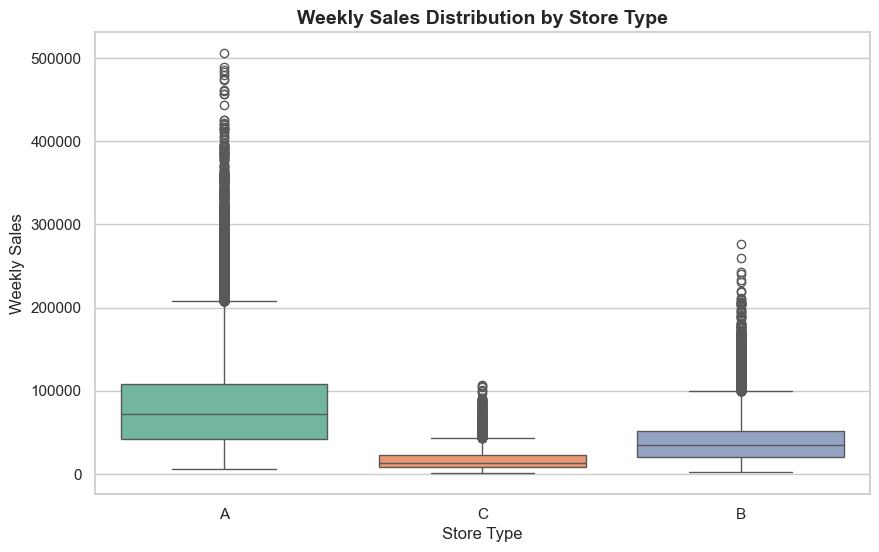

In [6]:
# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# 1. Box plot for Weekly Sales across Store Types
sns.boxplot(x='store_type', y='weekly_sales', data=master_df, palette='Set2')
plt.title('Weekly Sales Distribution by Store Type', fontsize=14, fontweight='bold')
plt.xlabel('Store Type', fontsize=12)
plt.ylabel('Weekly Sales', fontsize=12)

plt.show()

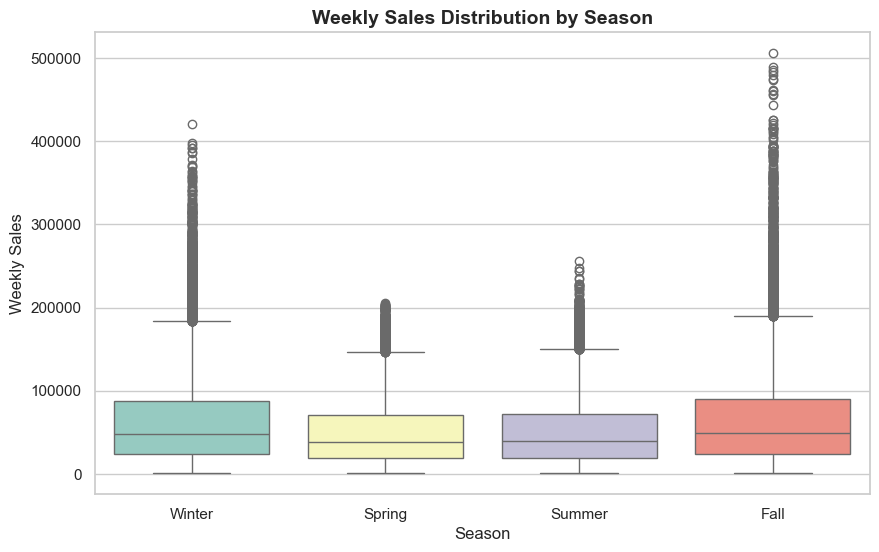

In [7]:
# Set up the figure size
plt.figure(figsize=(10, 6))

# Box plot for Weekly Sales across Seasons
sns.boxplot(x='season', y='weekly_sales', data=master_df, palette='Set3')
plt.title('Weekly Sales Distribution by Season', fontsize=14, fontweight='bold')
plt.xlabel('Season', fontsize=12)
plt.ylabel('Weekly Sales', fontsize=12)

plt.show()

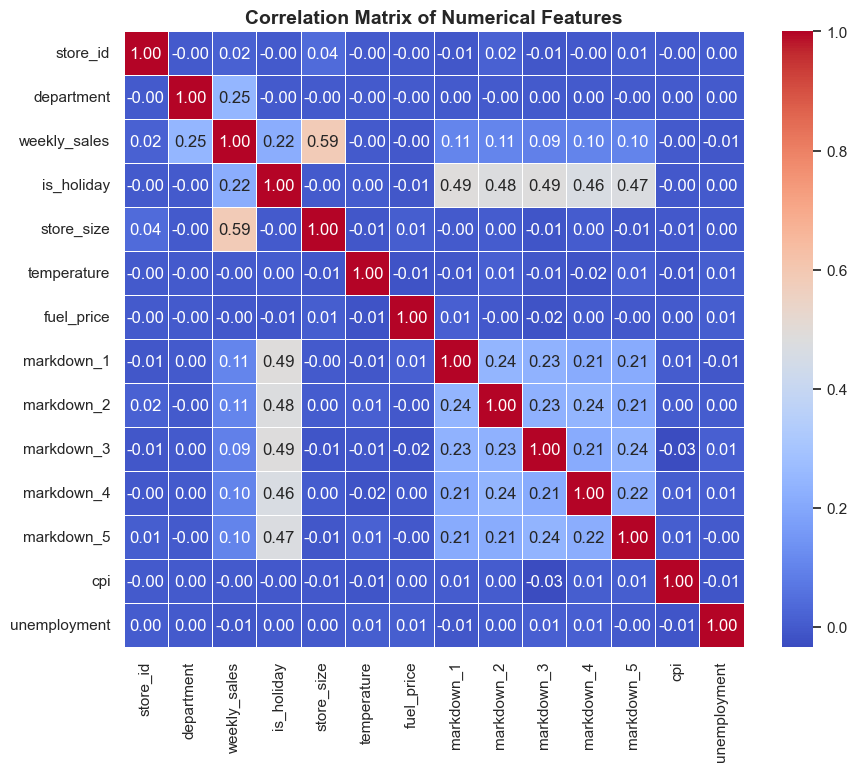

In [8]:
# Correlation Heatmap for numerical features
plt.figure(figsize=(10, 8))
numeric_cols = master_df.select_dtypes(include=['float64', 'int64']).columns
correlation_matrix = master_df[numeric_cols].corr()

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Numerical Features', fontsize=14, fontweight='bold')
plt.show()

In [9]:
# 1. Convert 'date' column to datetime format
master_df['date'] = pd.to_datetime(master_df['date'])

# 2. Sort values by store, department, and date for time-series consistency
master_df = master_df.sort_values(by=['store_id', 'department', 'date']).reset_index(drop=True)

# 3. Save the cleaned master dataset for model training phase
master_df.to_csv('master_cleaned_sales.csv', index=False)

print("Data preprocessing and EDA completed successfully!")
print(f"Final Cleaned Dataset Shape: {master_df.shape}")

Data preprocessing and EDA completed successfully!
Final Cleaned Dataset Shape: (156000, 18)
